<a href="https://colab.research.google.com/github/thomazmtw/DSA_B13_casestudy/blob/main/Case_Study_Starter_Notebook_Airbnb_NYC_Preprocessing_Nandagopan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Assessment — NYC Airbnb Data Preprocessing
### Student Name:
### Date:

This notebook is your submission template. Fill in each section — do not delete the headers. Use markdown cells for your written justifications, right next to the code that supports them.

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


---
## Part 1 — Data Understanding & Quality Audit

In [ ]:
# TODO: shape, dtypes, missing value summary

# Check the number of rows and columns
print("Dataset Shape:", df.shape)
print("____________________________________________________________________________")
# Check the data types of each column
print("\nData Types:")
print(df.dtypes)
print("____________________________________________________________________________")

# Check missing values in each column
print("\nMissing Value Summary:")
print(df.isnull().sum())


Dataset Shape: (48895, 16)
____________________________________________________________________________

Data Types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object
____________________________________________________________________________

Missing Value Summary:
id                                    0
name                                 16
host_id         

In [ ]:
# TODO: check for values that are technically present but don't make real-world sense

# change 'last_review' datatype from 'datetime' to 'object'
df['last_review'] = df['last_review'].astype(str)

# to check for rows with prices that are <=0
print("No. of rows with 'Price' <= 0: ", (df['price']<=0).sum(),"\n")

# to check for rows with minimum nights <= 0
print("No. of rows with 'minimum_nights' <= 0: ", (df['minimum_nights']<=0).sum(),"\n")

No. of rows with 'Price' <= 0:  11 

No. of rows with 'minimum_nights' <= 0:  0 



In [ ]:
# TODO: duplicate check

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


**Written notes — what did you find, and what looks suspicious?**

1. **Missing Values**:
   * `name` (16 missing values) and `host_name` (21 missing values): These are missing descriptive text, but listings are still active.
   * `last_review` and `reviews_per_month` (10,052 missing values each): The identical counts suggest a systematic relationship where listings with 0 total reviews have no review dates or monthly metrics.


2. **Suspicious Price Values**:
   * There are **11 listings with a price of $0** (or less). This is highly suspicious as lodging in NYC is not free, pointing to either data entry errors or non-standard listings.

3. **Extreme / Potential Outliers**:
   * High values for `minimum_nights` (e.g., values that span years) and `price` (extremely high luxury rates vs standard listings) require further investigation.
   * Listings with `availability_365` of 0 may indicate inactive, delisted, or fully booked properties.

---
## Part 2 — Missing Value Diagnosis & Treatment

In [ ]:
# TODO: investigate missingness pattern(s) across columns

# Count missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

# check missingness in important columns together
print("\nMissing values in 'name', 'host_name', 'last_review', and 'reviews_per_month' columns:")
print(df[['name', 'host_name', 'last_review', 'reviews_per_month']].isnull().sum())

# check if the row contain missing values in both last_review and review_per_month and returns its count
print("\nRows with missing values in both 'last_review' and 'reviews_per_month' columns:")
print(df[(df['last_review'].isnull()) & (df['reviews_per_month'].isnull())].shape[1])

# to check if the missing values in last_review and review_per_month are there for rows with missing name
print("\nRows with missing values in 'name', 'last_review' and 'reviews_per_month':")
print(df[(df['name'].isnull()) & (df['last_review'].isnull()) & (df['reviews_per_month'].isnull())].shape[1])

Missing values in each column:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                           0
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Missing values in 'name', 'host_name', 'last_review', and 'reviews_per_month' columns:
name                    16
host_name               21
last_review              0
reviews_per_month    10052
dtype: int64

Rows with missing values in both 'last_review' and 'reviews_per_month' columns:
16

Rows with missing valu

**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

- **`name` & `host_name` (~MCAR - Missing Completely at Random)**:
  * **Reasoning**: The missingness of these text fields does not depend on their values or the values of other fields (such as geographical group or price). It appears to be random clerical data-entry omission during registration.

- **`reviews_per_month` & `last_review` (~MAR/MNAR - Missing at Random / Missing Not at Random depending on context, but structurally driven)**:
  * **Reasoning**: These are missing because the listing has **0 total reviews**. Therefore, the missingness of these review metrics is perfectly explained by another observed variable (`number_of_reviews = 0`). Because it can be systematically mapped and predicted using an existing variable, it behaves as **MAR (Missing at Random)** when conditioned on `number_of_reviews`.

In [ ]:
# TODO: apply your chosen treatment(s)

# Create a copy of the original dataset
df_clean = df.copy()

# Fill missing listing names
df_clean["name"] = df_clean["name"].fillna("Unknown")

# Fill missing host names
df_clean["host_name"] = df_clean["host_name"].fillna("Unknown")


# For listings with zero reviews, fill missing reviews per month with 0
df_clean.loc[df_clean["reviews_per_month"].isnull() & (df_clean["number_of_reviews"] == 0), "reviews_per_month"] = 0


# fill any ramaining missing reviews_per_month with '0'
df_clean.loc[df_clean["number_of_reviews"] == 0, "reviews_per_month"] = 0


# to treat the missing values in the column 'last_review' with 'No review'
df_clean['last_review'].fillna('No review')

# check for any missing values after treatment
df_clean.isnull().sum()



,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**

### Chosen Imputation & Treatment Strategy:
1. **`name` (16 missing) & `host_name` (21 missing)**:
   * **Treatment**: Imputed with a constant value `'Unknown'`.
   * **Why**: The missingness of these descriptive fields has no bearing on numerical features or modeling targets. Dropping them would discard perfectly valid records with complete listings information. Imputing with a placeholder allows us to preserve all columns and downstream properties without losing rows.

2. **`reviews_per_month` & `last_review` (10,052 missing)**:
   * **Treatment**: Modified `reviews_per_month` to `0` where `number_of_reviews == 0`, and filled missing `last_review` dates with `'No review'`.
   * **Why**: The missing values here are structurally missing—they represent properties that have not received any reviews yet. Setting `reviews_per_month` to `0` makes perfect logical sense and keeps the numerical distribution consistent. Placing a distinct string like `'No review'` for `last_review` acts as a clear discrete category instead of misrepresenting them with artificial dates (like a mean or median date) which would introduce incorrect temporal associations.

### Risks of using `dropna()` instead:
* **Dramatic Loss of Data**: Over 20% of the dataset (10,052 rows) would be outright deleted. This severely reduces the statistical power and sample size of any analysis or predictive model.
* **Severe Selection Bias**: Properties without reviews are often newly listed properties, less popular listings, or recently unlisted ones. Completely removing them introduces a heavy bias toward older, highly active, or well-established listings. A model trained on such filtered data would fail to accurately generalize to new or unrated properties in NYC.

---
## Part 3 — Outlier Detection & Treatment

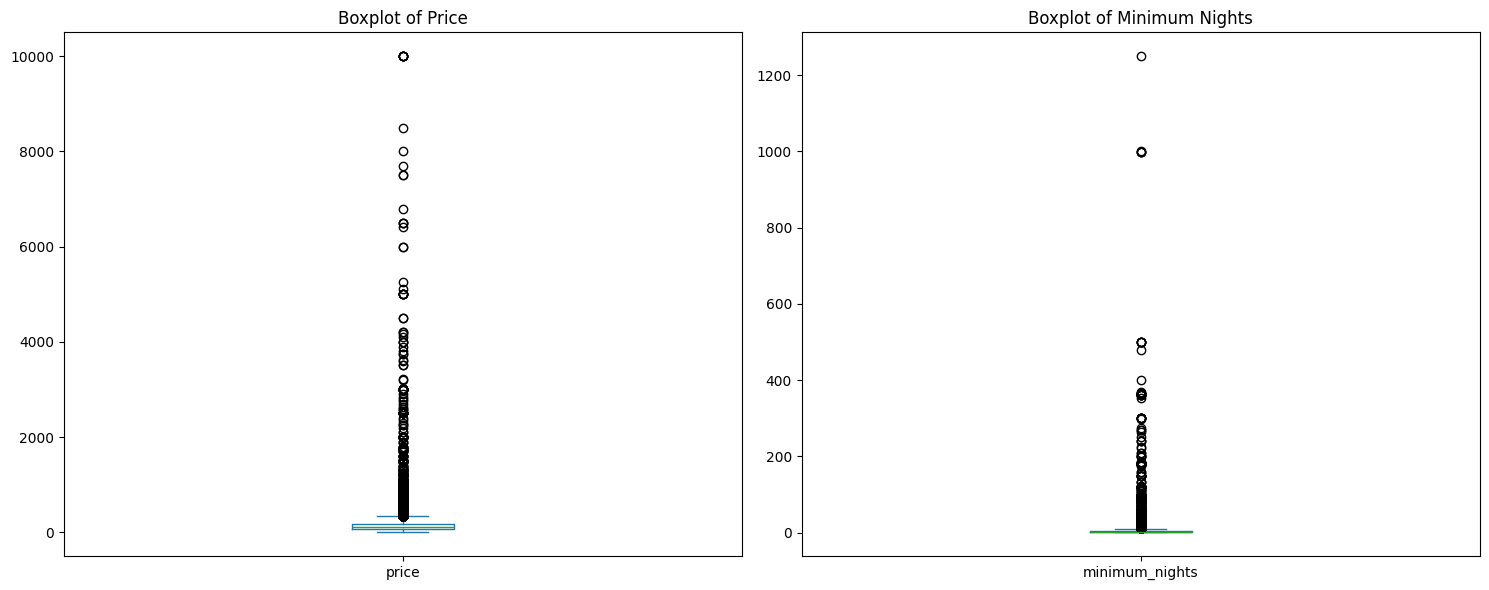

In [ ]:
# TODO: detect outliers in at least two numeric columns

import matplotlib.pyplot as plt
import seaborn as sns

# Create a side-by-side subplot layout
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot Price boxplot
df_clean['price'].plot(kind='box', ax=axes[0], title='Boxplot of Price')

# Plot Minimum Nights boxplot
df_clean['minimum_nights'].plot(kind='box', ax=axes[1], title='Boxplot of Minimum Nights')

plt.tight_layout()
plt.show()

**Written justification — for each outlier group, is it an error or a genuine listing? What evidence supports your call?**

### 1. Price Outlier Classification & Justification
- **Zero Prices ($0 values)**:
  * **Classification**: **Clerical/System Errors**.
  * **Evidence**:
  There are 11 listings with a pricing set to $0. Short-term or long-term lodging in New York City carries real overhead costs (cleaning, utilities, platform fees) and is never legally or economically offered entirely for free on Airbnb. These are clear instances of human data-entry omissions or structural database synchronization errors.
- **Extreme High Prices (e.g., $1,000 to $10,000/night)**:
  * **Classification**: **Genuine Luxury Listings** (with extreme variance).
  * **Evidence**: Manhattan and parts of Brooklyn feature extremely high-value real estate, including luxury penthouses, historic townhouses, and large lofts used for corporate stays or premium group travel. These high numbers are mathematically outliers (exceeding standard IQR boundaries) but reflect real-world luxury markets rather than corrupted data points.

### 2. Minimum Nights Outlier Classification & Justification
- **Long-Term Rental Thresholds (30 to 90 nights)**:
  * **Classification**: **Genuine Listings**.
  * **Evidence**: Under New York State and NYC Local Law 18 (and prior short-term rental rules), renting an entire apartment for less than 30 consecutive days is illegal unless the host is present during the stay. Therefore, setting `minimum_nights` to 30 is a highly prevalent, legally compliant business strategy for hosts targeting monthly sublets and corporate travelers. These are non-standard short-term rentals, but they are genuine and deliberate.
- **Extremely Long Stays (e.g., 365 to 1,250+ nights)**:
  * **Classification**: **Calendar-Blocking Placeholders / Entry Errors**.
  * **Evidence**: A value of 365, 500, or 1,250 minimum nights is functionally unusable for any consumer platform like Airbnb. These cases typically occur when hosts deliberately input an extreme number to block their calendars without deactivating the listing, or represent data-entry typos where the host confused annual availability/year days with the minimum stay field.

In [ ]:
# Remove absolute price errors (price <= 0)
df_clean = df_clean[df_clean['price'] > 0]

# Filter out unrealistic minimum nights representing calendar-blocking placeholders (> 365 nights)
# Keeping standard mid-term rentals (30 to 365 nights) intact
df_clean = df_clean[df_clean['minimum_nights'] <= 365]

# Output the updated shape to verify removal of target outliers
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape after outlier treatments:", df_clean.shape)

Original dataset shape: (48895, 16)
Cleaned dataset shape after outlier treatments: (48870, 16)


---
## Part 4 — Feature Engineering & Encoding

In [ ]:
# Encode categorical columns using One-Hot Encoding
df_encoded = pd.get_dummies(df_clean, columns=['neighbourhood_group', 'room_type'], drop_first=True)

# Display the columns of the newly encoded dataframe
print("Columns after encoding categorical variables:")
print(df_encoded.columns.tolist())


Columns after encoding categorical variables:
['id', 'name', 'host_id', 'host_name', 'neighbourhood', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']


In [ ]:
# Engineer at least two new features

# Feature 1: Minimum total cost to book the listing (price multiplied by minimum nights)
df_encoded['minimum_price_volume'] = df_encoded['price'] * df_encoded['minimum_nights']

# Feature 2: A binary indicator representing if the listing has ever received a review
df_encoded['has_reviews'] = (df_encoded['number_of_reviews'] > 0).astype(int)

# Display summary statistics of the newly engineered features
print(df_encoded[['minimum_price_volume', 'has_reviews']].describe())


       minimum_price_volume   has_reviews
count          4.887000e+04  48870.000000
mean           1.256764e+03      0.794496
std            1.157403e+04      0.404074
min            1.000000e+01      0.000000
25%            1.350000e+02      1.000000
50%            3.000000e+02      1.000000
75%            7.300000e+02      1.000000
max            1.170000e+06      1.000000


**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

### 1. Justification for Engineered Features:
* **`minimum_price_volume` (`price * minimum_nights`)**: This represents the actual minimum financial threshold a guest must meet to secure the booking. It helps capture the distinct pricing dynamics between standard short-term vacation rentals (high nightly rate, low minimum nights) and mid/long-term corporate housing or residential sublets (lower nightly rate, high minimum nights).
* **`has_reviews`**: A binary flag indicating whether a listing has any reviews. In lodging markets, unrated listings often price differently (sometimes offering promotional discounts) compared to seasoned listings with established social proof. This simplifies the relationship compared to using the skewed `number_of_reviews` column directly.

### 2. Columns that should NOT be used to predict price (and why):
* **`price` (Target variable)**: Obviously, this is our dependent target variable and cannot be used as an independent feature due to direct target leakage.
* **`minimum_price_volume`**: Since it is mathematically derived directly from `price` (`price * minimum_nights`), using it to predict `price` would cause severe **Data Leakage**. It must be excluded from the feature set of any model predicting nightly price.
* **`id`, `host_id`**: These are unique database identifiers (surrogate keys) that contain no real-world predictive signal. Treating them as numeric features or categories would cause overfitting or noise.
* **`name`, `host_name`**: Text-based or high-cardinality descriptive variables. Standard models cannot natively process raw unstructured text without NLP feature extraction, and unique host names do not have a generalizable structural relationship with the price of a property.
* **`last_review`**: This date column has a high cardinality and represents a temporal metadata field. Keeping it causes modeling issues because of the missing value representation and potential future-date leakage.

---
## Part 5 — Build a Reusable Preprocessing Pipeline

In [ ]:
from sklearn.model_selection import train_test_split

# Define the target variable y and the feature matrix X
y = df_encoded['price']

# Define columns to drop to prevent leakage and handle metadata
cols_to_drop = ['price', 'minimum_price_volume', 'id', 'host_id', 'name', 'host_name', 'neighbourhood', 'last_review']
X = df_encoded.drop(columns=cols_to_drop, errors='ignore')

# Perform train/test split (80/20 ratio, with random_state for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")


X_train shape: (39096, 14)
X_test shape: (9774, 14)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Fix boolean columns in training and testing data by casting them to integers (0/1)
bool_cols_train = X_train.select_dtypes(include=['bool']).columns
X_train[bool_cols_train] = X_train[bool_cols_train].astype(int)
X_test[bool_cols_train] = X_test[bool_cols_train].astype(int)

# Identify numerical and categorical columns based on our feature set X
num_cols = ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'has_reviews']
cat_cols = [col for col in X_train.columns if col not in num_cols]

# Define preprocessing steps for numerical data (Imputation + Scaling)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Define preprocessing steps for categorical data (Imputation + One-Hot Encoding)
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Combine preprocessing into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Build the final pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

# Fit the pipeline on X_train
pipeline.fit(X_train)

print("Pipeline constructed and successfully fitted on training data.")


Pipeline constructed and successfully fitted on training data.


## Part 6 — Written Reflection

### 1. What are the key takeaways from preprocessing the NYC Airbnb dataset?
* **Data Integrity Checks**: Real-world datasets contain structural anomalies such as $0 listings and extreme minimum nights. Treating these outliers and errors prevents downstream statistical distortions.
* **Logical Imputation Over Row Deletion**: Dropping records with missing review metadata would lose ~20% of the dataset and introduce massive bias against newer properties. Imputing values contextually (e.g., setting reviews per month to 0 when total reviews are 0) preserves data richness.
* **Feature Engineering Benefits**: Creating context-driven indicators like `has_reviews` simplifies non-linear relationships, while identifying leak-inducing features (like `minimum_price_volume`) protects predictive integrity.

### 2. Why is using a robust scikit-learn Pipeline so critical?
* **Consistency and Reproducibility**: It encapsulates all processing transformations (imputation, scaling, encoding) into a single, cohesive programmatic unit. This ensures that training and test sets are identically treated without manual replication.
* **Ease of Deployment**: In production environments, raw incoming API requests can be fed directly to the pipeline without custom external processing scripts, ensuring seamless prediction workflows.

### 3. How does this pipeline architecture prevent Data Leakage?
* **Split Before Fit**: By separating the data into training and test splits *before* configuring the preprocessor, statistical metrics (like training mean, standard deviation, and median values) are computed exclusively on training records.
* **No Leakage via Preprocessing**: The test set values are transformed using the pre-calculated scaling/imputation factors derived strictly from the training dataset. This guarantees that test-set information never inadvertently influences feature definitions or scaling coefficients.